# 로지스틱 회귀
* 독립 변수의 선형 결합을 이용해 특정 사건이 발생할 확률을 예측하여 **두 가지 또는 그 이상의 범주로 분류**하는 대표적인 지도학습 분류 기법
* 이름에 '회귀'가 들어가지만 실제로는 데이터를 특정 클래스로 분류하는 알고리즘
* 0 ~ 1 사이의 확률 값
* **시그모이드 함수**(Sigmoid Function) 또는 로지스틱 함수<br> <img src="https://drive.google.com/uc?id=106AKNodudz-T31DloPXSQluzTtkG0qmu" height=200 width=450>

## 데이터 준비하기
7가지 물고기의 데이터<br>
'Bream' 'Roach' 'Whitefish' 'Parkki' 'Perch' 'Pike' 'Smelt'


In [ ]:
# fish.csv 파일 코랩에 업로드
from google.colab import files
myfile = files.upload()

Saving fish.csv to fish (1).csv


In [ ]:
import pandas as pd

fish = pd.read_csv('fish.csv')
fish.head()

,Species,Weight,Length,Diagonal,Height,Width
0,Bream,242.0,25.4,30.0,11.5200,4.0200
1,Bream,290.0,26.3,31.2,12.4800,4.3056
2,Bream,340.0,26.5,31.1,12.3778,4.6961
3,Bream,363.0,29.0,33.5,12.7300,4.4555
4,Bream,430.0,29.0,34.0,12.4440,5.1340


In [ ]:
print(pd.unique(fish['Species']))

['Bream' 'Roach' 'Whitefish' 'Parkki' 'Perch' 'Pike' 'Smelt']


In [ ]:
fish_input = fish[['Weight','Length','Diagonal','Height','Width']].to_numpy()

In [ ]:
print(fish_input[:5])

[[242.      25.4     30.      11.52     4.02  ]
 [290.      26.3     31.2     12.48     4.3056]
 [340.      26.5     31.1     12.3778   4.6961]
 [363.      29.      33.5     12.73     4.4555]
 [430.      29.      34.      12.444    5.134 ]]


In [ ]:
fish_target = fish['Species'].to_numpy()

In [ ]:
from sklearn.model_selection import train_test_split

train_input, test_input, train_target, test_target = train_test_split(
    fish_input, fish_target, random_state=42)

In [ ]:
from sklearn.preprocessing import StandardScaler

ss = StandardScaler()
ss.fit(train_input)
train_scaled = ss.transform(train_input)
test_scaled = ss.transform(test_input)

## 다중분류: k-최근접 이웃 분류기의 확률 예측

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

kn = KNeighborsClassifier(n_neighbors=3)  # 이웃 3개 사용
kn.fit(train_scaled, train_target)

print(kn.score(train_scaled, train_target))
print(kn.score(test_scaled, test_target))

0.8907563025210085
0.85


In [ ]:
# 테스트 세트의 처음 5개 샘플 예측
print(kn.predict(test_scaled[:5]))

['Perch' 'Smelt' 'Pike' 'Perch' 'Perch']


In [ ]:
print(kn.classes_)

['Bream' 'Parkki' 'Perch' 'Pike' 'Roach' 'Smelt' 'Whitefish']


In [ ]:
# 예측 확률 출력
import numpy as np

proba = kn.predict_proba(test_scaled[:5])
print(np.round(proba, decimals=4))

[[0.     0.     1.     0.     0.     0.     0.    ]
 [0.     0.     0.     0.     0.     1.     0.    ]
 [0.     0.     0.     1.     0.     0.     0.    ]
 [0.     0.     0.6667 0.     0.3333 0.     0.    ]
 [0.     0.     0.6667 0.     0.3333 0.     0.    ]]


In [ ]:
# 테스트 세트의 3번 인덱스의 이웃은?
distances, indexes = kn.kneighbors(test_scaled[3:4])
print(train_target[indexes])

[['Roach' 'Perch' 'Perch']]


## 로지스틱 회귀


### 1)이 데이터셋의 로지스틱 회귀 모델이 학습한 방정식
$ z=a\times(Weight)+b\times(Length)+c\times(Diagonal)+d\times(Height)+e\times(Width)+f$<br><br>


### 2)로지스틱 회귀로 이진 분류하기

In [ ]:
# 인덱스값(True, False)을 이용하여 원하는 데이터만 추출하는 방법
char_arr = np.array(['A', 'B', 'C', 'D', 'E'])
print(char_arr[[True, False, True, False, False]])

['A' 'C']


In [ ]:
# Bream이나 Smelt만 추출하기 위한 준비
bream_smelt_indexes = (train_target == 'Bream') | (train_target == 'Smelt')

# bream_smelt_indexes값이 True인 인덱스의 데이터만 추출
train_bream_smelt = train_scaled[bream_smelt_indexes]
target_bream_smelt = train_target[bream_smelt_indexes]

In [ ]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression()
lr.fit(train_bream_smelt, target_bream_smelt)

LogisticRegression()

In [ ]:
# 훈련 세트의 처음 5개 샘플 예측
print(lr.predict(train_bream_smelt[:5]))

['Bream' 'Smelt' 'Bream' 'Bream' 'Bream']


In [ ]:
# 예측 확률 출력
print(lr.predict_proba(train_bream_smelt[:5]))

[[0.99760007 0.00239993]
 [0.02737325 0.97262675]
 [0.99486386 0.00513614]
 [0.98585047 0.01414953]
 [0.99767419 0.00232581]]


In [ ]:
print(lr.classes_)

['Bream' 'Smelt']


In [ ]:
# 2진 분류일 때 기울기와 절편
print(lr.coef_, lr.intercept_)
print(lr.coef_.shape, lr.intercept_.shape)

[[-0.40451732 -0.57582787 -0.66248158 -1.01329614 -0.73123131]] [-2.16172774]
(1, 5) (1,)


* $ z=-0.404\times(Weight)-0.576\times(Length)-0.663\times(Diagonal)-1.013\times(Height)-0.732\times(Width)-2.161$

### 3)시그모이드 함수(Sigmoid Function) 이해
* 로지스틱 회귀에서 2진 분류 시 클래스 결정하는 함수
* **시그모이드 함수**(Sigmoid Function) 또는 로지스틱 함수<br> <img src="https://drive.google.com/uc?id=106AKNodudz-T31DloPXSQluzTtkG0qmu" height=200 width=450>

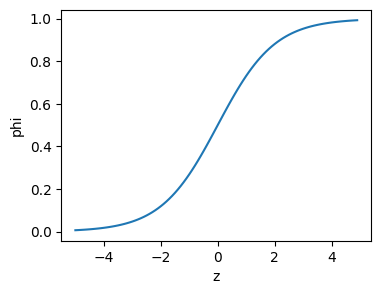

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

z = np.arange(-5, 5, 0.1)
phi = 1 / (1 + np.exp(-z))

plt.figure(figsize=(4, 3))
plt.plot(z, phi)
plt.xlabel('z')
plt.ylabel('phi')
plt.show()

In [ ]:
# 학습된 lr(로지스틱 회귀 모델)의 z 값
decisions = lr.decision_function(train_bream_smelt[:5])
print(decisions)

[-6.02991358  3.57043428 -5.26630496 -4.24382314 -6.06135688]


In [ ]:
# 파이썬의 사이파이 라이브러리를 활용한 시그모이드 함수
from scipy.special import expit

print(expit(decisions))
# 예측 결과 참고: ['Bream' 'Smelt' 'Bream' 'Bream' 'Bream']

[0.00239993 0.97262675 0.00513614 0.01414953 0.00232581]


### 4)로지스틱 회귀로 다중 분류하기
* 반복 회수(max_iter, 기본:100)가 부족하면 경고 발생할 수 있음
* 규제(C, 기본:1, alpha와 반대로 작을수록 규제 커짐): 릿지와 같이 계수의 제곱을 규제(L2 규제)

In [ ]:
lr = LogisticRegression(C=20, max_iter=1000)
lr.fit(train_scaled, train_target)

print(lr.score(train_scaled, train_target))
print(lr.score(test_scaled, test_target))

0.9327731092436975
0.925


In [ ]:
print(lr.predict(test_scaled[:5]))

['Perch' 'Smelt' 'Pike' 'Roach' 'Perch']


In [ ]:
proba = lr.predict_proba(test_scaled[:5])
print(np.round(proba, decimals=3))

[[0.    0.014 0.842 0.    0.135 0.007 0.003]
 [0.    0.003 0.044 0.    0.007 0.946 0.   ]
 [0.    0.    0.034 0.934 0.015 0.016 0.   ]
 [0.011 0.034 0.305 0.006 0.567 0.    0.076]
 [0.    0.    0.904 0.002 0.089 0.002 0.001]]


In [ ]:
print(lr.classes_)

['Bream' 'Parkki' 'Perch' 'Pike' 'Roach' 'Smelt' 'Whitefish']


In [ ]:
# 다중 분류일 때 기울기와 절편
print(lr.coef_, lr.intercept_)
print(lr.coef_.shape, lr.intercept_.shape)

[[-1.50605455 -1.03747913  2.60919713  7.6942274  -1.18603342]
 [ 0.19200046 -1.99988812 -3.79617725  6.5031264  -2.00022754]
 [ 3.55793539  6.36988929 -8.52233732 -5.75397233  3.79233438]
 [-0.11453309  3.61060121  3.94464503 -3.62243904 -1.75981679]
 [-1.40843717 -6.09242191  5.28629633 -0.86696569  1.84518455]
 [-1.33419949  1.48153392  1.38217547 -5.6602348  -4.39228964]
 [ 0.61328846 -2.33223526 -0.90379939  1.70625807  3.70084846]] [-0.10345047 -0.27281217  3.24444852 -0.17565069  2.64960025 -6.7204285
  1.37829306]
(7, 5) (7,)


### 5)소프트맥스 함수(Softmax function) 이해
* 로지스틱 회귀에서 다중 분류 시 클래스 결정하는 함수
* 시그모이드 함수는 하나의 방정식의 출력값을 0~1사이로 압축하다면,
* 소프트맥스 함수는 여러 개의 선형 방정식의 출력값을 0~1 사이로 압축하고 전체 합이 1이 되도록 만듦. 이를 위해 지수 함수를 사용하기 때문에 정규화된 지수 함수라고도 부름.<br>
$ e\_sum = e^{z1} + e^{z2} + e^{z3} + e^{z4} + e^{z5} + e^{z6} + e^{z7} $<br>
$ s1 = \frac{e^{z1}}{e\_sum}$, $ s2 = \frac{e^{z2}}{e\_sum}$, ... $ s7 = \frac{e^{z7}}{e\_sum}$


In [ ]:
decision = lr.decision_function(test_scaled[:5])
print(np.round(decision, decimals=2))

[[ -6.51   1.04   5.17  -2.76   3.34   0.35  -0.63]
 [-10.88   1.94   4.78  -2.42   2.99   7.84  -4.25]
 [ -4.34  -6.24   3.17   6.48   2.36   2.43  -3.87]
 [ -0.69   0.45   2.64  -1.21   3.26  -5.7    1.26]
 [ -6.4   -1.99   5.82  -0.13   3.5   -0.09  -0.7 ]]


In [ ]:
# 파이썬의 사이파이 라이브러리를 활용한 소프트맥스 함수 결과 확인
from scipy.special import softmax

proba = softmax(decision, axis=1)
print(np.round(proba, decimals=3))

# 결과 볼 때 참고
# 클래스 순서: 0        1        2       3      4       5       6
#              'Bream' 'Parkki' 'Perch' 'Pike' 'Roach' 'Smelt' 'Whitefish']
# 예측 결과: ['Perch' 'Smelt' 'Pike' 'Roach' 'Perch']

[[0.    0.014 0.842 0.    0.135 0.007 0.003]
 [0.    0.003 0.044 0.    0.007 0.946 0.   ]
 [0.    0.    0.034 0.934 0.015 0.016 0.   ]
 [0.011 0.034 0.305 0.006 0.567 0.    0.076]
 [0.    0.    0.904 0.002 0.089 0.002 0.001]]
